In [48]:
!pip install numpy matplotlib

In [49]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [50]:
def f(x):
    return 3*x**2 - 4*x + 5

In [51]:
f(3.0)

20.0

In [52]:
xs = np.arange(-5, 5, 0.25)
xs

array([-5.  , -4.75, -4.5 , -4.25, -4.  , -3.75, -3.5 , -3.25, -3.  ,
       -2.75, -2.5 , -2.25, -2.  , -1.75, -1.5 , -1.25, -1.  , -0.75,
       -0.5 , -0.25,  0.  ,  0.25,  0.5 ,  0.75,  1.  ,  1.25,  1.5 ,
        1.75,  2.  ,  2.25,  2.5 ,  2.75,  3.  ,  3.25,  3.5 ,  3.75,
        4.  ,  4.25,  4.5 ,  4.75])

In [53]:
ys = f(xs)
ys

array([100.    ,  91.6875,  83.75  ,  76.1875,  69.    ,  62.1875,
        55.75  ,  49.6875,  44.    ,  38.6875,  33.75  ,  29.1875,
        25.    ,  21.1875,  17.75  ,  14.6875,  12.    ,   9.6875,
         7.75  ,   6.1875,   5.    ,   4.1875,   3.75  ,   3.6875,
         4.    ,   4.6875,   5.75  ,   7.1875,   9.    ,  11.1875,
        13.75  ,  16.6875,  20.    ,  23.6875,  27.75  ,  32.1875,
        37.    ,  42.1875,  47.75  ,  53.6875])

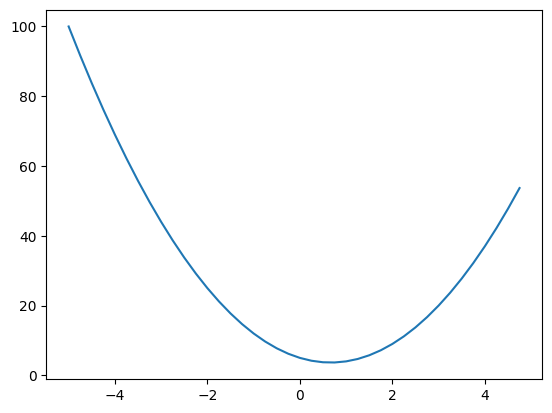

In [54]:
plt.plot(xs, ys)

In [ ]:
h=0.000000001
x=3.0
f(x)

In [ ]:
f(x+h)

In [ ]:
(f(x+h) - f(x))/h

In [ ]:
x=-3.0
(f(x+h) - f(x))/h

In [ ]:
x=2/3
(f(x+h) - f(x))/h

In [ ]:
a = 2.0
b = -3.0
c = 10.0
d = a*b + c
print(d)

In [ ]:
h=0.000000001
a = 2.0
b = -3.0
c = 10.0
d1 = a*b + c
a += h
d2 = a*b + c
print('d1', d1)
print('d2', d2)
print('slope', (d2-d1)/h)

In [ ]:
h=0.000000001
a = 2.0
b = -3.0
c = 10.0
d1 = a*b + c
b += h
d2 = a*b + c
print('d1', d1)
print('d2', d2)
print('slope', (d2-d1)/h)

In [ ]:
h=0.000000001
a = 2.0
b = -3.0
c = 10.0
d1 = a*b + c
c += h
d2 = a*b + c
print('d1', d1)
print('d2', d2)
print('slope', (d2-d1)/h)

In [183]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')
        
        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        
        return out

    def __neg__(self):
        return self * (-1)

    def __sub__(self, other):
        return self + (-other)

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        
        return out

    def __rmul__(self, other):
        return self * other

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data**other, (self,), f'**{other}')

        def _backward():
            self.grad += other * (self.data**(other-1)) * out.grad 
        out._backward = _backward
        
        return out
    
    def __truediv__(self, other):
        return self * (other**-1)
    
    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t, (self,), 'tanh')

        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        
        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self,), 'exp')

        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward
        
        return out

    def backward(self):
        topo=[]
        visited=set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

In [148]:
a = Value(2.0)
b = Value(4.0)
a-b

Value(data=-8.0)

In [149]:
a/b
#a * (1/b)
a * (b**-1)

Value(data=0.5)

In [150]:
!pip install micrograd

In [151]:
!pip install graphviz

In [152]:
from graphviz import Digraph

def trace(root):
  #set of all nodes and edges
  nodes,edges =set(),set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child,v))
        build(child)
  build(root)
  return nodes,edges


def draw_dot(root):
  dot=Digraph(format='svg', graph_attr={'rankdir':'LR'})

  nodes,edges=trace(root)
  for n in nodes:
    uid=str(id(n))
    dot.node(name=uid, label="{%s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      dot.node(name=uid+n._op, label=n._op)
      dot.edge(uid+n._op, uid)

  for n1, n2 in edges:
    dot.edge(str(id(n1)), str(id(n2))+n2._op)

  return dot

In [153]:
#2 dimensional input neural networks
#inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

#weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

#bias of the neuron
b =  Value(6.8813735870195432, label='b')

#x1w1 + x2w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'

#activation function tanh
o=n.tanh(); o.label='o'
o.backward()

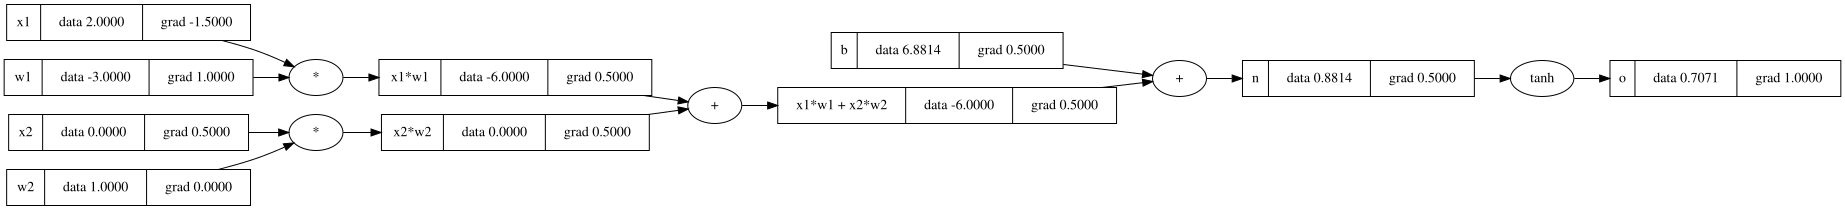

In [154]:
draw_dot(o)

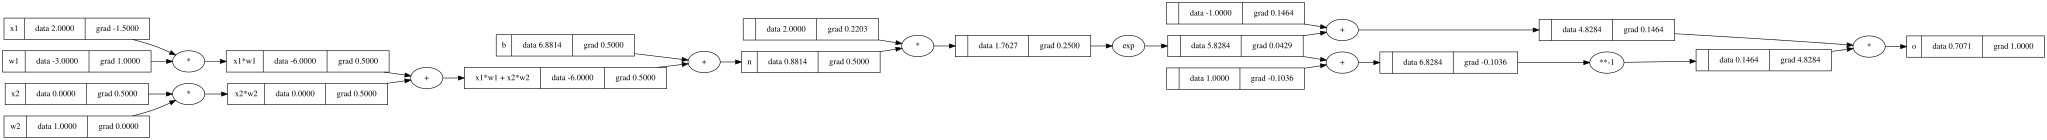

In [157]:
#2 dimensional input neural networks
#inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

#weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

#bias of the neuron
b =  Value(6.8813735870195432, label='b')

#x1w1 + x2w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'

#activation function tanh
e=(2*n).exp()
o=(e-1)/(e+1)

o.label='o'
o.backward()
draw_dot(o)

In [160]:
!pip install torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 797.1/797.1 MB 20.6 MB/s eta 0:00:00m eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.6/410.6 MB 26.2 MB/s eta 0:00:00m eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 29.2 MB/s eta 0:00:00 MB/s eta 0:00:0101
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 28.2 MB/s eta 0:00:00m eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 823.6/823.6 kB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 20.3 MB/s eta 0:00:00m eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.6/121.6 MB 32.2 MB/s eta 0:00:00m eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.5/56.5 MB 20.2 MB/s eta 0:00:00m eta 0:00:010:0105m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 124.2/124.2 MB 29.9 MB/s eta 0:00:00m eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 196.0/196.0 MB 27.4 MB/s eta 0:00:00m eta 0:00:010:01:02
   ━━━━━━━━━━━━━━

In [161]:
import torch

In [163]:
x1 = torch.Tensor([2.0]).double(); x1.requires_grad = True
x2 = torch.Tensor([0.0]).double(); x2.requires_grad = True

w1 = torch.Tensor([-3.0]).double(); w1.requires_grad = True
w2 = torch.Tensor([1.0]).double(); w2.requires_grad = True

b = torch.Tensor([6.8813735870195432]).double(); b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('---')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [166]:
o

tensor([0.7071], dtype=torch.float64, grad_fn=<TanhBackward0>)

In [167]:
o.data

tensor([0.7071], dtype=torch.float64)

In [168]:
o.data.item()

0.7071066904050358

In [172]:
x1

tensor([2.], dtype=torch.float64, requires_grad=True)

In [173]:
x1.grad

tensor([-1.5000], dtype=torch.float64)

In [174]:
x1.grad.item()

-1.5000003851533106

In [179]:
import random 

class Neuron:
    
    def __init__(self,nin):  #nin - number of input to this neuron
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)] # create a list of random weights of nin size
        self.b = Value(random.uniform(-1,1))
    
    def __call__(self,x):  #this enable the call to n(x)
        #x = m * x + b
        return 0.0

x = [2.0, 3.0]
n = Neuron(2)
n(x)

0.0

In [194]:
import random 

class Neuron:
    
    def __init__(self,nin):  #nin - number of input to this neuron
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)] # create a list of random weights of nin size
        self.b = Value(random.uniform(-1,1))
    
    def __call__(self,x):  #this enable the call to n(x)
        #x = m * x + b
        #print(list(zip(self.w, x)))  #take the first value of w and put it with first value of x
        #act = sum(wi*xi for wi, xi in zip(self.w,x)) + self.b # act = activation
        act = sum((wi*xi for wi,xi in zip(self.w,x)), self.b)
        out = act.tanh()
        return out

class Layer:

    def __init__(self,nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)] #nout - number of outputs (neurons) in this layer

    def __call__(self,x):
        outs = [n(x) for n in self.neurons]
        return outs

x = [2.0, 3.0]
n = Layer(2, 3)  # 2 inputs to each neurons with 3 output neurons in each layer
n(x)

[Value(data=-0.8384209412755242),
 Value(data=-0.9498264687320459),
 Value(data=-0.5996685103115423)]

In [200]:
import random 

class Neuron:
    
    def __init__(self,nin):  #nin - number of input to this neuron
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)] # create a list of random weights of nin size
        self.b = Value(random.uniform(-1,1))
    
    def __call__(self,x):  #this enable the call to n(x)
        #x = m * x + b
        #print(list(zip(self.w, x)))  #take the first value of w and put it with first value of x
        #act = sum(wi*xi for wi, xi in zip(self.w,x)) + self.b # act = activation
        act = sum((wi*xi for wi,xi in zip(self.w,x)), self.b)
        out = act.tanh()
        return out

class Layer:

    def __init__(self,nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)] #nout - number of outputs (neurons) in this layer

    def __call__(self,x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

class MLP:

    def __init__(self,nin, nouts):
        sz = [nin] + nouts
        print(sz)
        print(len(nouts))
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self,x):
        for layer in self.layers:
            x = layer(x)
        return x

x = [2.0, 3.0, -1.0]  # 3 inputs in input layer
n = MLP(3, [4,4,1])   # 3 inputs to this MLP, 4 hidden layer 1, 4 hidden layer 2, 1 output layer
n(x)

[3, 4, 4, 1]
3


Value(data=-0.8942865596761364)

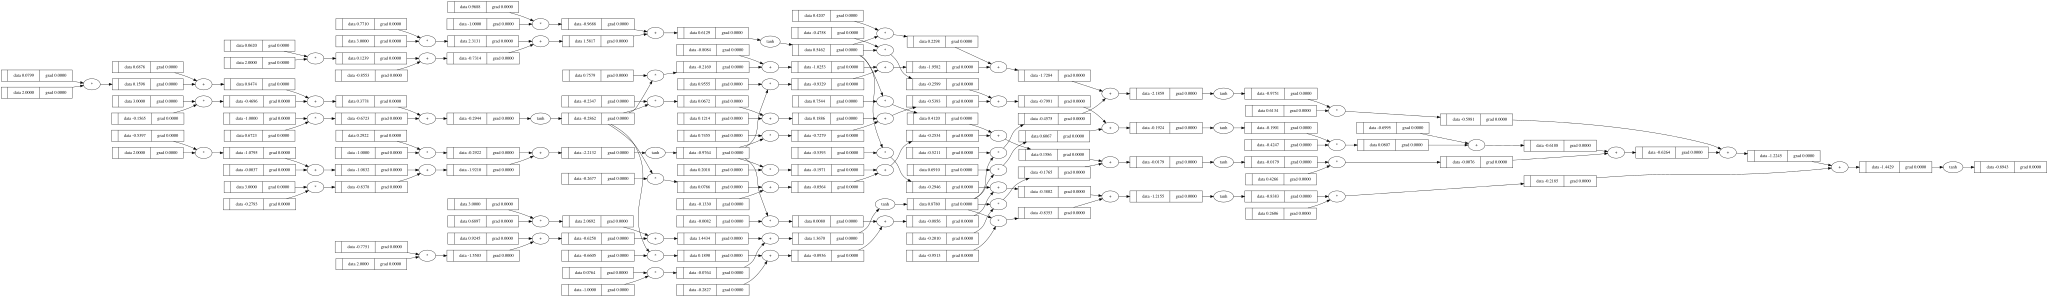

In [201]:
draw_dot(n(x))